# 11 顕熱交換と全熱交換

外気と還気の熱回収を、顕熱／全熱で比較する。

## 到達目標
Tsa=Toa+ηt(Tra−Toa)、xsa=xoa+ηx(xra−xoa)。顕熱モードのηxは0。

## 実行環境
Python 3.10以上とvtsimnx engineが必要です。Colabのlocalhostは手元PCのサーバーを指しません。次の設定セルのAPI URLを到達可能なものに変更します。APIキーは環境変数で渡し、ノートに保存しません。

検証engine commit: `5eeffb2f8012a2fe41bca705450b0dd0a952326d`。入力モデルは実計算確認済ですが、原住宅の年間再現とは範囲が異なります。

## 実行版の使い方
このノートは検証対象のvtsimnx commit 5eeffb2f8012a2fe41bca705450b0dd0a952326d に合わせた代表教材です。上から順に実行します。
Pythonクライアントの導入だけではengineは起動しません。教材17以外は接続可能なengineと、必要に応じてVTSIMNX_API_KEYが必要です。Colabの127.0.0.1は手元PCのengineを指しません。
入力はノート内に含めています。元のDriveパスや測定CSVを別途読む必要はありません。
出力は教材フォルダ内のresults/11/に保存します。詳しい準備は同じフォルダの00_実行ガイド.ipynbを参照してください。


In [1]:
import os, sys, subprocess
# 検証runnerのみ専用環境で導入済みの依存を再利用する。通常はこのセルで導入する。
if os.environ.get("VTSIMNX_TUTORIAL_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip", "setuptools>=68,<81", "wheel"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "vtsimnx @ git+https://github.com/iguchi-lab/vtsimnx@5eeffb2f8012a2fe41bca705450b0dd0a952326d",
        "matplotlib", "japanize-matplotlib"])


In [2]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from IPython.display import display
import vtsimnx as vt

# ローカルJupyterでは、ノートブックと同じフォルダを作業フォルダにする。
DATA_DIR = Path(os.environ.get("VTSIMNX_TUTORIAL_DATA", ".")).expanduser().resolve()
BASE_URL = os.environ.get("VTSIMNX_API_URL", "http://127.0.0.1:8000")
API_KEY = os.environ.get("VTSIMNX_API_KEY")
OUTPUT = DATA_DIR / "results" / "11"
OUTPUT.mkdir(parents=True, exist_ok=True)


## 入力を読む
次の辞書はvtsimnxのネイティブ形式です。風量はm³/s、熱量はW、熱容量はJ/Kです。

In [3]:
configs = {'11_hrv_sensible': {'builder': {},
                     'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                              'end': '2026-01-01T23:00:00',
                                              'length': 24,
                                              'timestep': 3600}},
                     'nodes': [{'key': 'outside', 't': 5, 'x': 0.003},
                               {'key': 'room',
                                'calc_t': True,
                                't': 20,
                                'v': 100,
                                'thermal_mass': 120720,
                                'x': 0.008,
                                'calc_x': True}],
                     'ventilation_branches': [],
                     'thermal_branches': [{'key': 'outside->room',
                                           'source': 'outside',
                                           'target': 'room',
                                           'conductance': 50}],
                     'heat_source': [{'key': 'internal',
                                      'room': 'room',
                                      'generation_rate': 500,
                                      'convection': 1,
                                      'radiation': 0}],
                     'heat_recovery_vent': [{'key': 'HRV',
                                             'outdoor': 'outside',
                                             'room': 'room',
                                             'vol': 0.027777777777777776,
                                             'recovery': 'sensible',
                                             'eta_t': 0.75,
                                             'eta_x': 0.6}]},
 '11_hrv_total': {'builder': {},
                  'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                           'end': '2026-01-01T23:00:00',
                                           'length': 24,
                                           'timestep': 3600}},
                  'nodes': [{'key': 'outside', 't': 5, 'x': 0.003},
                            {'key': 'room',
                             'calc_t': True,
                             't': 20,
                             'v': 100,
                             'thermal_mass': 120720,
                             'x': 0.008,
                             'calc_x': True}],
                  'ventilation_branches': [],
                  'thermal_branches': [{'key': 'outside->room',
                                        'source': 'outside',
                                        'target': 'room',
                                        'conductance': 50}],
                  'heat_source': [{'key': 'internal',
                                   'room': 'room',
                                   'generation_rate': 500,
                                   'convection': 1,
                                   'radiation': 0}],
                  'heat_recovery_vent': [{'key': 'HRV',
                                          'outdoor': 'outside',
                                          'room': 'room',
                                          'vol': 0.027777777777777776,
                                          'recovery': 'total',
                                          'eta_t': 0.75,
                                          'eta_x': 0.6}]}}


## 実行と結果の取得
計算ごとの要求JSONを保存し、必要な系列をDataFrameとして取得します。

In [4]:
results = {}
for name, config in configs.items():
    results[name] = vt.run_calc(BASE_URL, config, api_key=API_KEY,
        as_result=True, raise_on_error=True, timeout=1800, request_output_path=OUTPUT / (name + "_request.json"))
    print(name, results[name].artifact_dir)


11_hrv_sensible artifacts.1794699416122.output.7336f1c4dbb141f3ba4c4201ae2abc21


11_hrv_total artifacts.1794699417178.output.244d60f32788439dadeb4e2c44ec03d9


11_hrv_sensible


,HRV,HRV_exhaust,outside,room,room_air,void
time,,,,,,
2026-01-01 00:00:00,0.003,0.005500,0.003,0.005500,0.0,0.0
2026-01-01 01:00:00,0.003,0.004250,0.003,0.004250,0.0,0.0
2026-01-01 02:00:00,0.003,0.003625,0.003,0.003625,0.0,0.0
2026-01-01 03:00:00,0.003,0.003312,0.003,0.003312,0.0,0.0
2026-01-01 04:00:00,0.003,0.003156,0.003,0.003156,0.0,0.0


11_hrv_total


,HRV,HRV_exhaust,outside,room,room_air,void
time,,,,,,
2026-01-01 00:00:00,0.005143,0.006571,0.003,0.006571,0.0,0.0
2026-01-01 01:00:00,0.004531,0.005551,0.003,0.005551,0.0,0.0
2026-01-01 02:00:00,0.004093,0.004822,0.003,0.004822,0.0,0.0
2026-01-01 03:00:00,0.003781,0.004302,0.003,0.004302,0.0,0.0
2026-01-01 04:00:00,0.003558,0.003930,0.003,0.003930,0.0,0.0


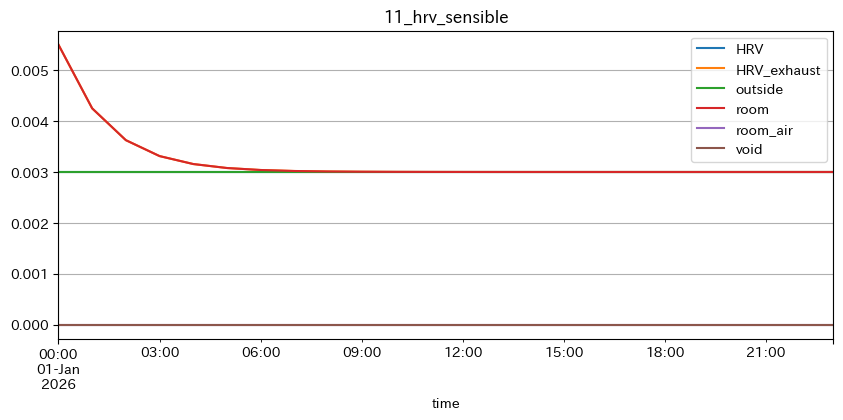

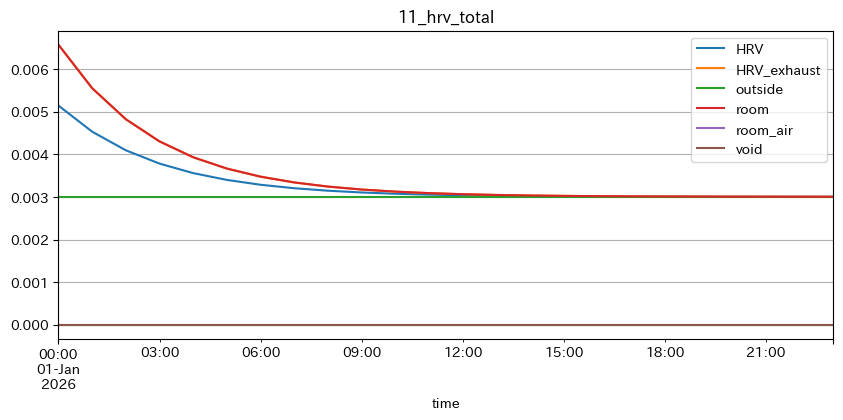

In [5]:
frames = {name: result.get_series_df('humidity_x', raise_on_error=True) for name, result in results.items()}
for name, frame in frames.items():
    print(name)
    display(frame.head())
    frame.to_csv(OUTPUT / (name + "_humidity_x.csv"), encoding="utf-8-sig")
    frame.plot(title=name, figsize=(10, 4), grid=True)


## 確認・発展
回収率と換気量を変え、室温湿度と回収熱量を調べる。

保存された時刻の値は当該ステップ更新後の値です。初期値との比較ではこの差に注意します。

## 原典との対応


S番号は原典調査時の識別子です。原典の完全な台帳は管理者のDrive整理資料に保管しています。